In [1]:
# install required packages

!pip install ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 110.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3


In [2]:
# download dataset

from pathlib import Path
from google.colab import userdata
from roboflow import Roboflow

project_folder = Path("/content/ODOL")

raw_dataset_folder = project_folder / "dataset" / "raw"
source_dataset = raw_dataset_folder / "truck-over-dimension"

raw_dataset_folder.mkdir(parents=True, exist_ok=True)

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
roboflow = Roboflow(api_key=ROBOFLOW_API_KEY)

workspace = roboflow.workspace("sigara-hpnoo")
dataset_project = workspace.project("truck-over-dimension-brupr")
dataset_version = dataset_project.version(2)

dataset = dataset_version.download(
    "yolov8",
    location=str(source_dataset)
)

source_dataset = Path(dataset.location)

source_dataset

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/ODOL/dataset/raw/truck-over-dimension in yolov8:: 100%|██████████| 5718/5718 [00:01<00:00, 3016.09it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


PosixPath('/content/ODOL/dataset/raw/truck-over-dimension')

In [3]:
# prepare pipeline folders

models_folder = project_folder / "models"

results_folder = project_folder / "results" / "pipeline"
image_results_folder = results_folder / "images"
video_results_folder = results_folder / "videos"

models_folder.mkdir(parents=True, exist_ok=True)
image_results_folder.mkdir(parents=True, exist_ok=True)
video_results_folder.mkdir(parents=True, exist_ok=True)

models_folder

PosixPath('/content/ODOL/models')

In [4]:
# upload trained models

from google.colab import files

uploaded_models = files.upload()

for model_name in uploaded_models:
    uploaded_model_path = Path(model_name)
    destination_path = models_folder / model_name

    uploaded_model_path.replace(destination_path)

models_folder

Saving best.pt to best.pt
Saving mobilenet_odol_classifier.keras to mobilenet_odol_classifier.keras


PosixPath('/content/ODOL/models')

In [5]:
# load trained models

from ultralytics import YOLO
from tensorflow.keras.models import load_model

yolo_model_path = models_folder / "best.pt"

classifier_model_path = (
    models_folder
    / "mobilenet_odol_classifier.keras"
)

yolo_model = YOLO(yolo_model_path)
classifier_model = load_model(classifier_model_path)

In [6]:
# configure detection and classification

detection_threshold = 0.30

not_odol_threshold = 0.40
odol_threshold = 0.60

minimum_crop_size = 80
history_length = 5

prediction_history = {}

# detection_threshold: batas confidence deteksi YOLO.
# not_odol_threshold: skor ODOL ≤ 0.40 diberi label NOT ODOL.
# odol_threshold: skor ODOL ≥ 0.60 diberi label ODOL. Di antara kedua batas, label UNCERTAIN.
# minimum_crop_size: crop harus memiliki width dan height minimal 80 pixels agar diklasifikasikan.
# history_length: simpan maksimal 5 prediksi terakhir per truck ID untuk dirata-ratakan.
# prediction_history: dictionary penyimpan riwayat tersebut.

In [7]:
# process one image or video frame

import cv2
import numpy as np

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def process_frame(frame, tracking=False):
    output_frame = frame.copy()
    frame_height, frame_width = frame.shape[:2]

    # detect trucks
    if tracking:
        results = yolo_model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=detection_threshold,
            imgsz=640,
            verbose=False
        )

    else:
        results = yolo_model(
            frame,
            conf=detection_threshold,
            imgsz=640,
            verbose=False
        )

    # process each detected truck
    for box in results[0].boxes:
        coordinates = box.xyxy[0].cpu().numpy().astype(int)

        left, top, right, bottom = coordinates
        detection_confidence = box.conf[0].item()

        # keep boundaries inside the frame

        left = max(0, left)
        top = max(0, top)
        right = min(frame_width, right)
        bottom = min(frame_height, bottom)

        if right <= left or bottom <= top:
            continue

        # get truck tracking ID when available

        if box.id is not None:
            truck_id = int(box.id.item())
            truck_name = f"Truck {truck_id}"

        else:
            truck_id = None
            truck_name = "Truck"

        # crop the detected truck

        truck_crop = frame[top:bottom, left:right]
        crop_height, crop_width = truck_crop.shape[:2]

        # skip classification when the crop is too small

        if (
            crop_width < minimum_crop_size
            or crop_height < minimum_crop_size
        ):
            text = (
                f"{truck_name} | TOO FAR"
                f" | Detection {detection_confidence:.1%}"
            )

            color = (0, 165, 255)

        else:
            # prepare crop for MobileNetV2

            rgb_crop = cv2.cvtColor(
                truck_crop,
                cv2.COLOR_BGR2RGB
            )

            resized_crop = cv2.resize(
                rgb_crop,
                (224, 224)
            )

            classifier_input = resized_crop.astype(np.float32)

            classifier_input = np.expand_dims(
                classifier_input,
                axis=0
            )

            classifier_input = preprocess_input(classifier_input)

            # predict ODOL probability

            predictions = classifier_model.predict(
                classifier_input,
                verbose=0
            )

            odol_probability = predictions[0][0].item()

            # average recent predictions for tracked trucks

            if truck_id is not None:
                if truck_id not in prediction_history:
                    prediction_history[truck_id] = []

                prediction_history[truck_id].append(
                    odol_probability
                )

                prediction_history[truck_id] = (
                    prediction_history[truck_id][-history_length:]
                )

                average_probability = np.mean(
                    prediction_history[truck_id]
                )

            else:
                average_probability = odol_probability

            # choose classification label and color

            if average_probability >= odol_threshold:
                text = (
                    f"{truck_name} | ODOL {average_probability:.1%}"
                    f" | Detection {detection_confidence:.1%}"
                )

                color = (0, 0, 255)

            elif average_probability <= not_odol_threshold:
                not_odol_probability = 1 - average_probability

                text = (
                    f"{truck_name} | NOT ODOL {not_odol_probability:.1%}"
                    f" | Detection {detection_confidence:.1%}"
                )

                color = (0, 255, 0)

            else:
                text = (
                    f"{truck_name} | UNCERTAIN"
                    f" | ODOL score {average_probability:.1%}"
                )

                color = (0, 255, 255)

        # position the label

        text_size, baseline = cv2.getTextSize(
            text,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            2
        )

        text_width = text_size[0]

        text_x = max(
            0,
            min(left, frame_width - text_width - 10)
        )

        text_y = max(top - 10, 30)

        # draw bounding box and label

        cv2.rectangle(
            output_frame,
            (left, top),
            (right, bottom),
            color,
            3
        )

        cv2.putText(
            output_frame,
            text,
            (text_x, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            color,
            2
        )

    return output_frame

In [8]:
# prepare evaluation settings

import yaml

from sklearn.model_selection import train_test_split

match_threshold = 0.50

data_yaml = source_dataset / "data.yaml"

dataset_information = yaml.safe_load(
    data_yaml.read_text()
)

class_names = dataset_information["names"]

if class_names != ["NOT ODOL", "ODOL"]:
    raise ValueError(
        "Expected class 0 = NOT ODOL and class 1 = ODOL."
    )

if not 0 <= not_odol_threshold < odol_threshold <= 1:
    raise ValueError(
        "The classification thresholds are invalid."
    )

print("Class names:", class_names)
print("Box matching threshold:", match_threshold)


Class names: ['NOT ODOL', 'ODOL']
Box matching threshold: 0.5


In [9]:
# read annotations from one label file

def read_annotations(label_file):
    annotations = []

    label_lines = label_file.read_text().splitlines()

    for line_number, label_line in enumerate(label_lines, start=1):
        if not label_line.strip():
            continue

        label_values = label_line.split()
        class_value = label_values[0]

        # check class ID

        if class_value not in ["0", "1"]:
            raise ValueError(
                f"Unknown class: {label_file}, line {line_number}"
            )

        class_id = int(class_value)

        # convert coordinates into numbers

        coordinates = []

        for value in label_values[1:]:
            coordinates.append(float(value))

        if not np.isfinite(coordinates).all():
            raise ValueError(
                f"Invalid coordinates: {label_file}, line {line_number}"
            )

        # read a bounding box

        if len(coordinates) == 4:
            center_x, center_y, box_width, box_height = coordinates

            left = center_x - box_width / 2
            top = center_y - box_height / 2
            right = center_x + box_width / 2
            bottom = center_y + box_height / 2

        # find a bounding box around a polygon

        elif len(coordinates) >= 6 and len(coordinates) % 2 == 0:
            x_coordinates = []
            y_coordinates = []

            for coordinate_index in range(0, len(coordinates), 2):
                x_coordinates.append(coordinates[coordinate_index])
                y_coordinates.append(coordinates[coordinate_index + 1])

            left = min(x_coordinates)
            top = min(y_coordinates)
            right = max(x_coordinates)
            bottom = max(y_coordinates)

        else:
            raise ValueError(
                f"Invalid annotation: {label_file}, line {line_number}"
            )

        # check whether boundaries are outside the image

        if (
            left < -0.000001
            or top < -0.000001
            or right > 1.000001
            or bottom > 1.000001
        ):
            raise ValueError(
                f"Box outside image: {label_file}, line {line_number}"
            )

        # keep boundaries between zero and one

        left = max(0, left)
        top = max(0, top)
        right = min(1, right)
        bottom = min(1, bottom)

        if right <= left or bottom <= top:
            raise ValueError(
                f"Empty box: {label_file}, line {line_number}"
            )

        box = [left, top, right, bottom]

        annotations.append(
            (class_id, box)
        )

    return annotations

In [10]:
# calculate overlap between two boxes

def calculate_iou(box_a, box_b):
    left_a, top_a, right_a, bottom_a = box_a
    left_b, top_b, right_b, bottom_b = box_b

    # find the overlapping rectangle

    overlap_left = max(left_a, left_b)
    overlap_top = max(top_a, top_b)
    overlap_right = min(right_a, right_b)
    overlap_bottom = min(bottom_a, bottom_b)

    overlap_width = max(0, overlap_right - overlap_left)
    overlap_height = max(0, overlap_bottom - overlap_top)

    overlap_area = overlap_width * overlap_height

    # calculate each box area

    area_a = (right_a - left_a) * (bottom_a - top_a)
    area_b = (right_b - left_b) * (bottom_b - top_b)

    combined_area = area_a + area_b - overlap_area

    # calculate intersection over union

    if combined_area > 0:
        iou = overlap_area / combined_area
    else:
        iou = 0

    return iou

In [11]:
# group images and annotations

image_groups = {}

for split_name in ["train", "valid", "test"]:
    image_folder = source_dataset / split_name / "images"
    label_folder = source_dataset / split_name / "labels"

    for image_file in sorted(image_folder.glob("*.jpg")):
        label_file = label_folder / f"{image_file.stem}.txt"

        annotations = read_annotations(label_file)

        original_name = image_file.stem.split(".rf.")[0]

        if original_name not in image_groups:
            image_groups[original_name] = []

        image_groups[original_name].append(
            (image_file, annotations)
        )

print("Total groups:", len(image_groups))

Total groups: 1095


In [12]:
# identify groups containing ODOL

group_names = sorted(image_groups.keys())
group_labels = []

for group_name in group_names:
    contains_odol = False

    for image_file, annotations in image_groups[group_name]:
        for class_id, box in annotations:
            if class_id == 1:
                contains_odol = True
                break

        if contains_odol:
            break

    if contains_odol:
        group_labels.append(1)
    else:
        group_labels.append(0)

print("Total groups:", len(group_names))

Total groups: 1095


In [13]:
# split groups into training, validation, and test

train_groups, remaining_groups, train_labels, remaining_labels = (
    train_test_split(
        group_names,
        group_labels,
        test_size=0.30,
        stratify=group_labels,
        random_state=42
    )
)

valid_groups, test_groups = train_test_split(
    remaining_groups,
    test_size=0.50,
    stratify=remaining_labels,
    random_state=42
)

print("Train groups:", len(train_groups))
print("Validation groups:", len(valid_groups))
print("Test groups:", len(test_groups))

Train groups: 766
Validation groups: 164
Test groups: 165


In [14]:
# select one labelled image from each test group

test_files = []
skipped_unlabelled = 0

for group_name in sorted(test_groups):
    labelled_images = []

    # collect images that contain annotations

    for image_file, annotations in image_groups[group_name]:
        if annotations:
            labelled_images.append(
                (image_file, annotations)
            )

    if not labelled_images:
        skipped_unlabelled += 1
        continue

    # prefer an image without ".rf." in its filename

    original_images = []

    for image_file, annotations in labelled_images:
        if ".rf." not in image_file.stem:
            original_images.append(
                (image_file, annotations)
            )

    # select one image from the group

    if original_images:
        selected_image = original_images[0]
    else:
        selected_image = labelled_images[0]

    test_files.append(selected_image)

if not test_files:
    raise ValueError(
        "No labelled test images were found."
    )

print("Selected test images:", len(test_files))
print("Skipped unlabelled groups:", skipped_unlabelled)

Selected test images: 122
Skipped unlabelled groups: 43


In [15]:
# evaluate detected trucks

# reset results before every evaluation run
total_trucks = 0
matched_trucks = 0
missed_trucks = 0
extra_detections = 0

correct = 0
wrong = 0
uncertain = 0
too_small = 0

matrix = np.zeros((2, 2), dtype=int)

for image_file, annotations in test_files:
    frame = cv2.imread(str(image_file))

    if frame is None:
        raise ValueError(
            f"Cannot read image: {image_file}"
        )

    frame_height, frame_width = frame.shape[:2]

    # convert annotation boxes into pixel coordinates

    true_boxes = []
    true_classes = []

    for class_id, box in annotations:
        left = box[0] * frame_width
        top = box[1] * frame_height
        right = box[2] * frame_width
        bottom = box[3] * frame_height

        true_boxes.append(
            [left, top, right, bottom]
        )

        true_classes.append(class_id)

    total_trucks += len(true_boxes)

    matched = [False] * len(true_boxes)

    # detect trucks with YOLO

    results = yolo_model(
        frame,
        conf=detection_threshold,
        imgsz=640,
        verbose=False
    )

    # process highest-confidence detections first

    detections = sorted(
        results[0].boxes,
        key=lambda detection: detection.conf[0].item(),
        reverse=True
    )

    for detection in detections:
        coordinates = detection.xyxy[0].cpu().numpy()

        if not np.isfinite(coordinates).all():
            raise ValueError(
                f"Invalid predicted box: {image_file}"
            )

        left, top, right, bottom = coordinates.astype(int)

        # keep detection boundaries inside the image

        left = max(0, left)
        top = max(0, top)
        right = min(frame_width, right)
        bottom = min(frame_height, bottom)

        predicted_box = [left, top, right, bottom]

        # find the best unmatched annotation

        best_index = None
        best_iou = match_threshold

        for annotation_index, true_box in enumerate(true_boxes):
            if matched[annotation_index]:
                continue

            iou = calculate_iou(
                predicted_box,
                true_box
            )

            if iou >= best_iou:
                best_iou = iou
                best_index = annotation_index

        # count detections without a matching annotation

        if best_index is None:
            extra_detections += 1
            continue

        matched[best_index] = True
        matched_trucks += 1

        true_class = true_classes[best_index]

        # skip classification when the crop is too small

        crop_width = right - left
        crop_height = bottom - top

        if (
            crop_width < minimum_crop_size
            or crop_height < minimum_crop_size
        ):
            too_small += 1
            continue

        # prepare truck crop for MobileNetV2

        truck_crop = frame[top:bottom, left:right]

        rgb_crop = cv2.cvtColor(
            truck_crop,
            cv2.COLOR_BGR2RGB
        )

        resized_crop = cv2.resize(
            rgb_crop,
            (224, 224)
        )

        classifier_input = resized_crop.astype(np.float32)

        classifier_input = np.expand_dims(
            classifier_input,
            axis=0
        )

        classifier_input = preprocess_input(classifier_input)

        # predict ODOL probability

        predictions = classifier_model.predict(
            classifier_input,
            verbose=0
        )

        odol_probability = predictions[0][0].item()

        if (
            not np.isfinite(odol_probability)
            or not 0 <= odol_probability <= 1
        ):
            raise ValueError(
                f"Invalid classification score: {image_file}"
            )

        # choose predicted class

        if odol_probability >= odol_threshold:
            predicted_class = 1

        elif odol_probability <= not_odol_threshold:
            predicted_class = 0

        else:
            uncertain += 1
            continue

        # record classification result

        matrix[true_class, predicted_class] += 1

        if predicted_class == true_class:
            correct += 1
        else:
            wrong += 1

    # count annotations that YOLO did not match

    missed_trucks += matched.count(False)

In [16]:
# show evaluation counts

classified = correct + wrong

print("Evaluated images:", len(test_files))
print("Skipped unlabelled groups:", skipped_unlabelled)

print()
print("Annotated trucks:", total_trucks)
print("Matched detections:", matched_trucks)
print("Missed trucks:", missed_trucks)
print("Extra detections:", extra_detections)

print()
print("Too small:", too_small)
print("Uncertain:", uncertain)
print("Correct classifications:", correct)
print("Wrong classifications:", wrong)

print()
print("Confusion matrix:")
print("Rows = true, columns = predicted")
print("0 = NOT ODOL, 1 = ODOL")
print(matrix)

Evaluated images: 122
Skipped unlabelled groups: 43

Annotated trucks: 131
Matched detections: 95
Missed trucks: 36
Extra detections: 39

Too small: 1
Uncertain: 4
Correct classifications: 74
Wrong classifications: 16

Confusion matrix:
Rows = true, columns = predicted
0 = NOT ODOL, 1 = ODOL
[[38 12]
 [ 4 36]]


In [17]:
# calculate evaluation metrics

if classified > 0:
    classification_accuracy = correct / classified

    print(
        "Accuracy on matched, classified trucks:",
        round(classification_accuracy, 4)
    )

if total_trucks > 0:
    detection_recall = matched_trucks / total_trucks
    decision_coverage = classified / total_trucks
    correct_decision_rate = correct / total_trucks

    print(
        f"Detection recall at IoU {match_threshold:.2f}:",
        round(detection_recall, 4)
    )

    print(
        "Decision coverage:",
        round(decision_coverage, 4)
    )

    print(
        "Correct decisions / all annotated trucks:",
        round(correct_decision_rate, 4)
    )

total_detections = matched_trucks + extra_detections

if total_detections > 0:
    detection_precision = matched_trucks / total_detections

    print(
        f"Detection precision at IoU {match_threshold:.2f}:",
        round(detection_precision, 4)
    )

Accuracy on matched, classified trucks: 0.8222
Detection recall at IoU 0.50: 0.7252
Decision coverage: 0.687
Correct decisions / all annotated trucks: 0.5649
Detection precision at IoU 0.50: 0.709


In [18]:
# check test image folder

test_image_folder = source_dataset / "test" / "images"

print("Test image folder:", test_image_folder)
print("Folder exists:", test_image_folder.is_dir())

Test image folder: /content/ODOL/dataset/raw/truck-over-dimension/test/images
Folder exists: True


Saving VID_20210816_164254 22.jpg to VID_20210816_164254 22 (1).jpg


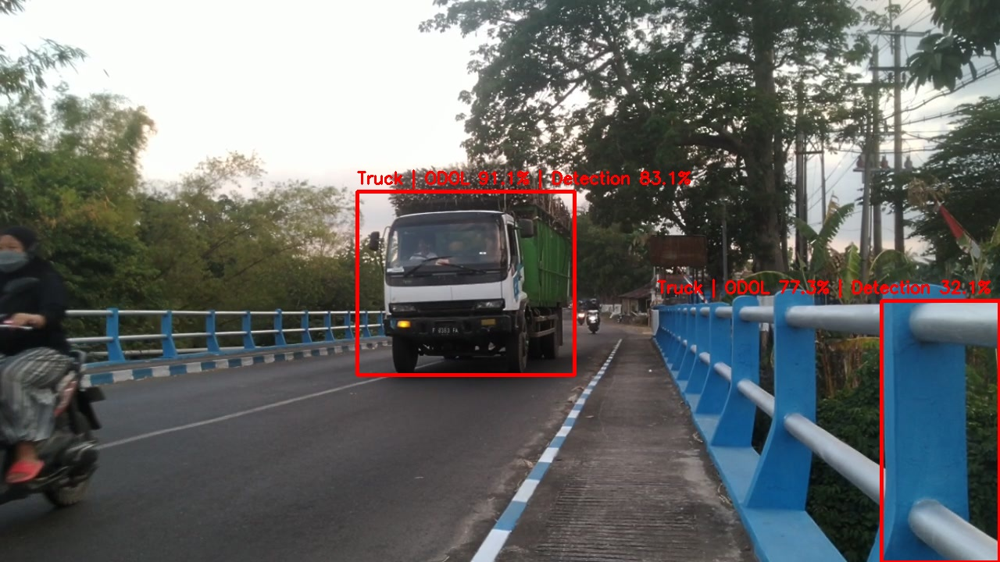

In [21]:
# upload and process images

from IPython.display import display, Image

uploaded_images = files.upload()

for image_name in uploaded_images:
    image_path = Path(image_name)

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(
            f"Cannot read image: {image_path}"
        )

    result_image = process_frame(image)

    result_filename = f"{image_path.stem}_result.jpg"
    output_path = image_results_folder / result_filename

    cv2.imwrite(
        str(output_path),
        result_image
    )

    display(
        Image(
            filename=str(output_path),
            width=900
        )
    )

In [22]:
# download the last processed image

files.download(str(output_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# upload and prepare video

uploaded_videos = files.upload()

video_names = list(uploaded_videos.keys())
video_name = video_names[0]

video_path = Path(video_name)
output_video_path = video_results_folder / "odol_result.mp4"

video = cv2.VideoCapture(str(video_path))

if not video.isOpened():
    raise ValueError(
        f"Cannot open video: {video_path}"
    )

# read video properties

fps = video.get(cv2.CAP_PROP_FPS)

frame_width = int(
    video.get(cv2.CAP_PROP_FRAME_WIDTH)
)

frame_height = int(
    video.get(cv2.CAP_PROP_FRAME_HEIGHT)
)

# prepare output video writer

video_codec = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(
    str(output_video_path),
    video_codec,
    fps,
    (frame_width, frame_height)
)

if not video_writer.isOpened():
    video.release()

    raise ValueError(
        f"Cannot create output video: {output_video_path}"
    )

print("Video:", video_name)
print("FPS:", fps)
print("Frame size:", frame_width, frame_height)

Saving 37379-413555939.mp4 to 37379-413555939.mp4
Video: 37379-413555939.mp4
FPS: 25.0
Frame size: 1920 1080


In [25]:
# process video frames

prediction_history.clear()

try:
    while True:
        success, frame = video.read()

        if not success:
            break

        result_frame = process_frame(
            frame,
            tracking=True
        )

        video_writer.write(result_frame)

finally:
    video.release()
    video_writer.release()

output_video_path

PosixPath('/content/ODOL/results/pipeline/videos/odol_result.mp4')

In [27]:
# convert video for notebook playback

import subprocess

from IPython.display import Video, display

playable_video_path = (
    video_results_folder
    / "odol_result_playable.mp4"
)

subprocess.run(
    [
        "ffmpeg",
        "-y",
        "-loglevel", "error",
        "-i", str(output_video_path),
        "-vcodec", "libx264",
        "-pix_fmt", "yuv420p",
        str(playable_video_path)
    ],
    check=True
)

display(
    Video(
        str(playable_video_path),
        embed=True,
        width=900
    )
)

In [28]:
# download result video

files.download(str(playable_video_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>